# 02 · Extensões de domínio

**Objetivo:** ver como cada área da fábrica acrescenta seu vocabulário **sem redefinir o núcleo**. Produção, manutenção, qualidade, energia e estoque são arquivos separados que importam `core.ttl` e apenas adicionam classes e relações.

Por que separar? Porque cada domínio tem um dono diferente (PCP, manutenção, qualidade, utilidades, almoxarifado) e evolui em ritmo diferente. O núcleo é o acordo mínimo entre eles.

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
pd.set_option("display.max_colwidth", 80)
from lab.graph import load_ontology, load_plant, query, MFG, PRD, MNT, QA, NRG, INV, ID
from lab.graph import DOMAINS
from rdflib import OWL, RDFS, RDF

## 1. O que cada extensão traz

In [2]:
linhas = []
nucleo = load_ontology(domains=[])
for d in DOMAINS:
    g = load_ontology(domains=[d])
    novas = set(g.subjects(RDF.type, OWL.Class)) - set(nucleo.subjects(RDF.type, OWL.Class))
    rels = [p for p in g.subjects(RDF.type, OWL.ObjectProperty) if (p, None, None) not in nucleo]
    herda = sorted({str(g.value(c, RDFS.subClassOf)).split("#")[-1] for c in novas if g.value(c, RDFS.subClassOf)})
    linhas.append({"domínio": d, "classes novas": ", ".join(sorted(str(c).split("#")[-1] for c in novas)),
                   "relações novas": len(rels), "estende do núcleo": ", ".join(herda)})
pd.DataFrame(linhas)

,domínio,classes novas,relações novas,estende do núcleo
0,production,"Lot, Product, ProductionRun, WorkOrder",4,Event
1,maintenance,"Component, Downtime, FailureMode, MaintenanceOrder",4,"Asset, Event"
2,quality,"DefectType, Finding, Inspection",3,Event
3,energy,"Consumption, EnergyMeter",2,"DataPoint, Event"
4,inventory,"Material, MaterialLot",2,


**Leitura**

* `ProductionRun`, `Downtime`, `MaintenanceOrder`, `Inspection` e `Consumption` estendem `Event` do núcleo: todos herdam **quando** e **onde** (`startTime`, `endTime`, `occurredOn`). É isso que permite cruzar paradas com corridas de produção pelo tempo.
* `Component` estende `Asset`: um rolamento entra na hierarquia ISA-95 abaixo da máquina.
* `EnergyMeter` estende `DataPoint`: um medidor tem tópico no UNS como qualquer tag.

## 2. O esquema completo como grafo

Cada caixa é uma classe, cada seta cheia é uma relação (`domain → range`) e cada seta tracejada é `subClassOf`. As molduras agrupam por domínio.

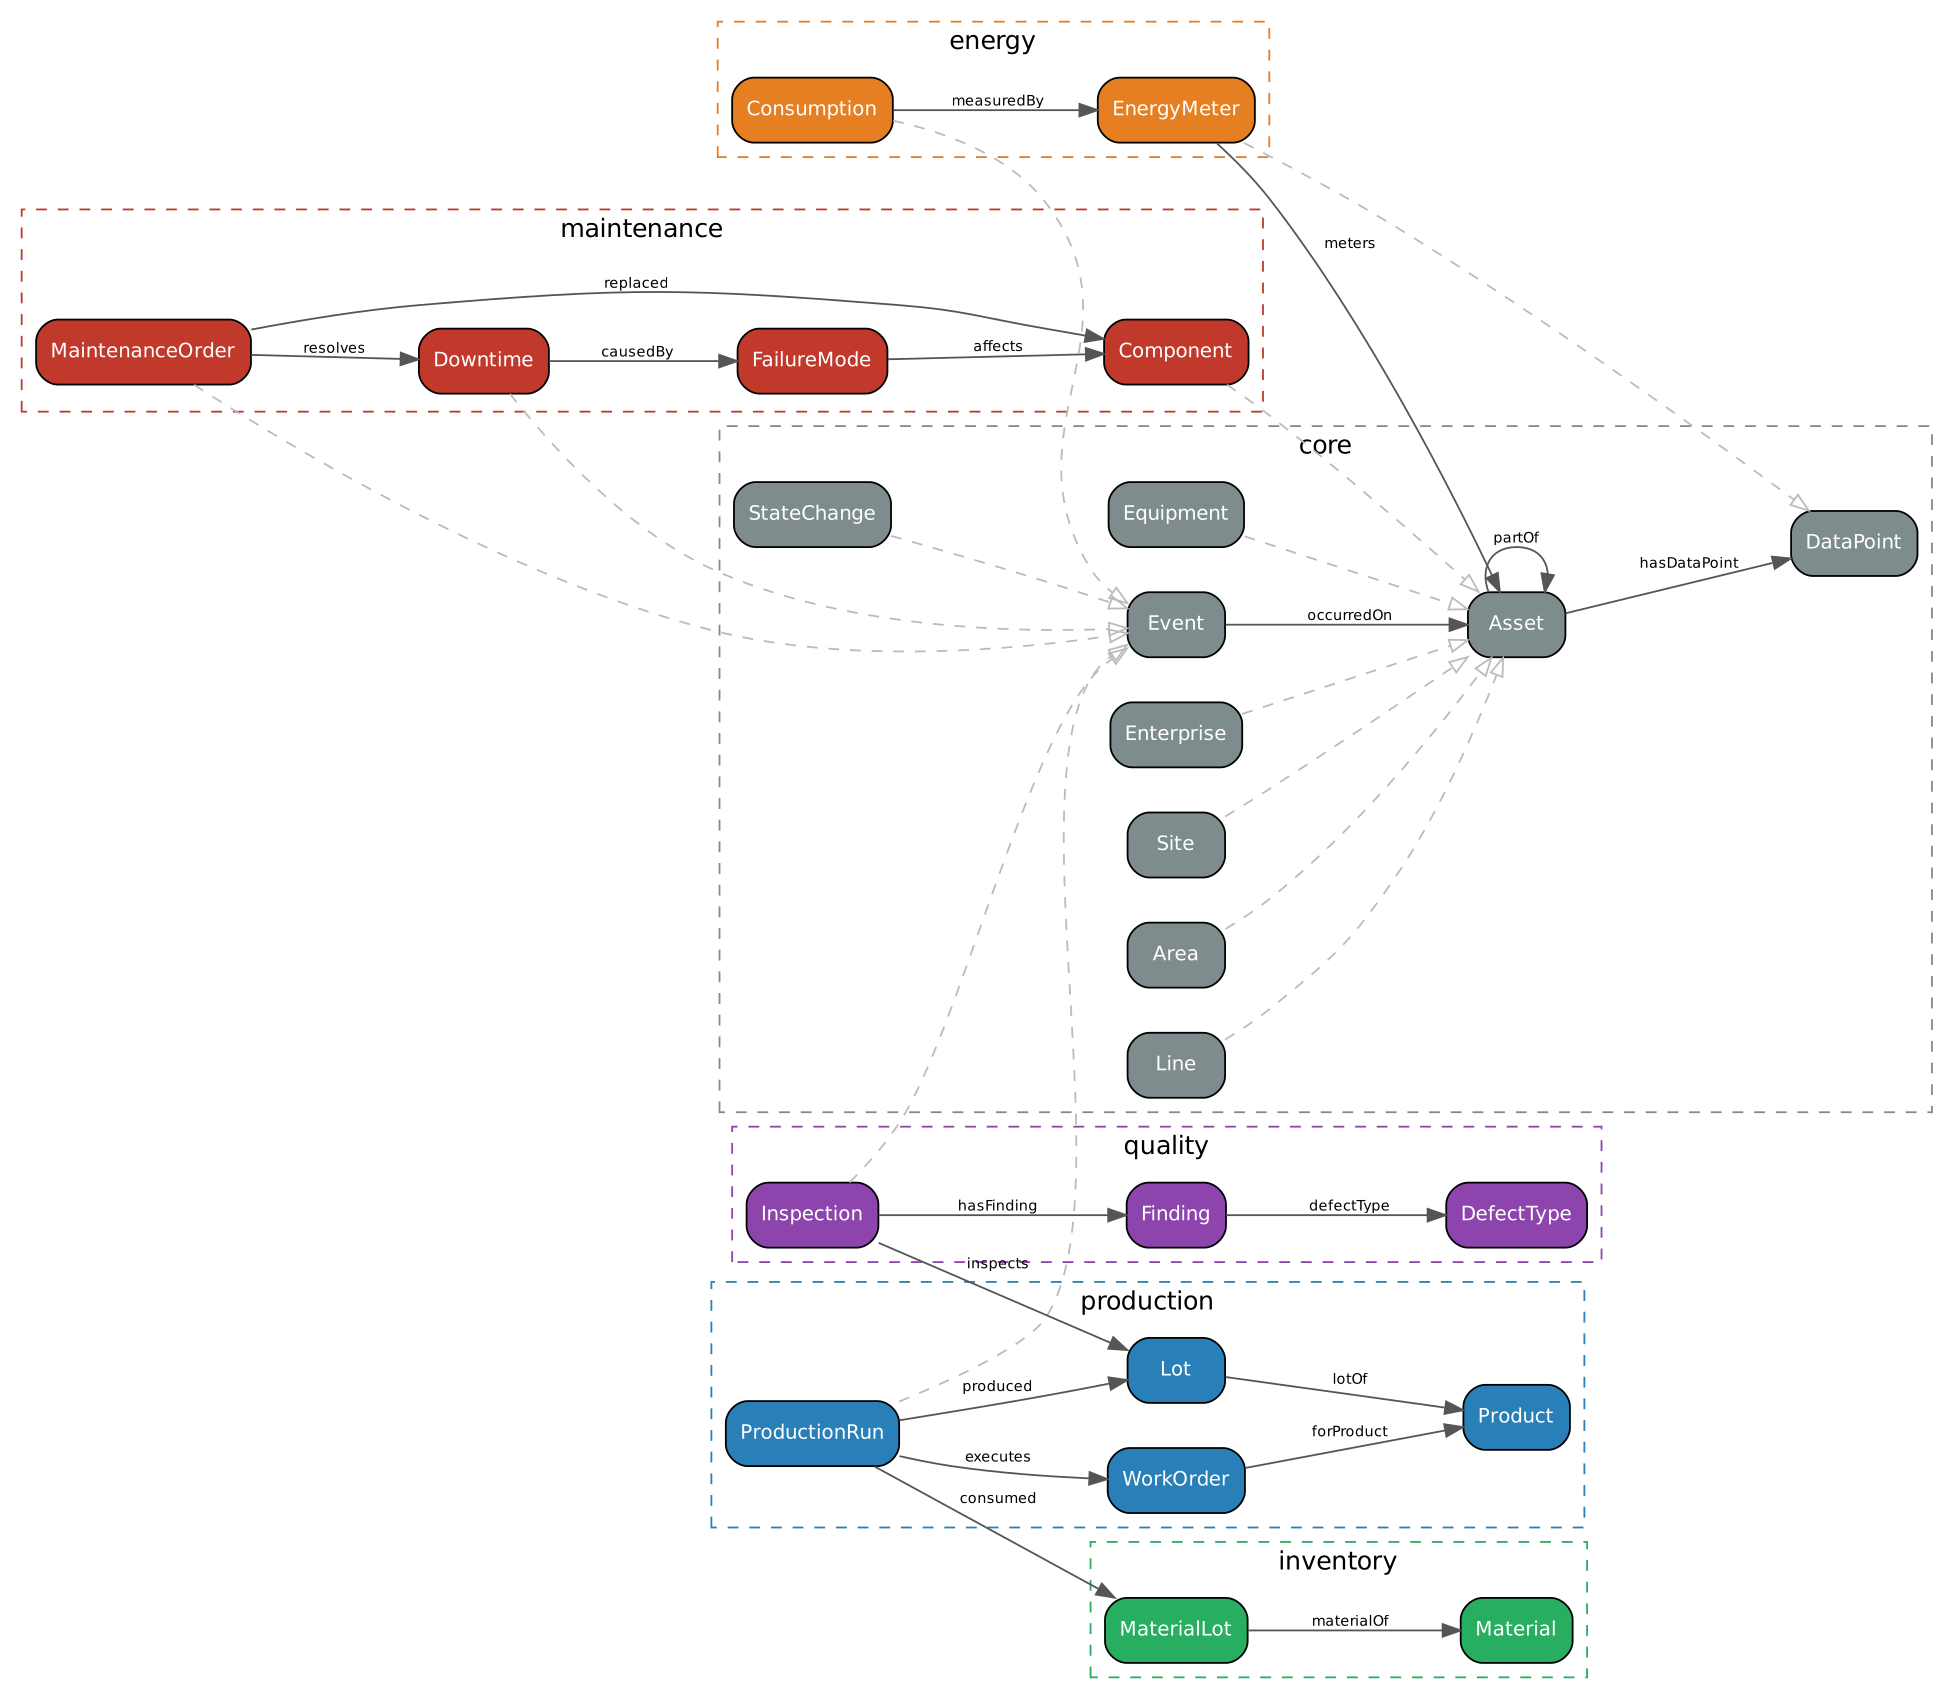

In [3]:
from IPython.display import Image
from lab import figures
Image(filename=figures.render(figures.schema_dot(load_ontology()), "schema"))

Todas as extensões convergem para os nós cinza do núcleo (`Equipment`, `Event`, `Asset`, `DataPoint`). É essa convergência que faz o grafo ser **um** e não cinco bancos de dados lado a lado.

## 3. Como os domínios aparecem nos dados

In [4]:
g = load_plant()
contagem = query(g, '''
SELECT ?classe (COUNT(?x) AS ?instancias) WHERE {
  ?x a ?c . FILTER(STRSTARTS(STR(?x), STR(id:)))
  BIND(REPLACE(STR(?c), "^.*/(.*)$", "$1") AS ?classe)
} GROUP BY ?classe ORDER BY ?classe''')
pd.DataFrame(contagem)

,classe,instancias
0,core#Area,2
1,core#DataPoint,27
2,core#Enterprise,1
3,core#Equipment,9
4,core#Line,3
5,core#Site,2
6,energy#Consumption,3
7,energy#EnergyMeter,3
8,inventory#Material,1
9,inventory#MaterialLot,3


## 4. Um registro de cada domínio, lado a lado

Uma corrida de produção, a parada que aconteceu durante ela, e a inspeção do lote que ela gerou. Três sistemas diferentes no mundo real (MES, CMMS, QMS), três nós ligados aqui.

In [5]:
for iri in ["run/R-1042", "downtime/D-001", "inspection/Q-1042"]:
    print(f"--- {iri}")
    for p, o in sorted(g.predicate_objects(ID[iri])):
        print(f"   {g.namespace_manager.normalizeUri(p):<18} {str(o).split('/id/')[-1]}")

--- run/R-1042
   rdf:type           https://w3id.org/industrial-ontology-lab/production#ProductionRun
   rdfs:label         R-1042
   mfg:endTime        2026-11-10T10:00:00+00:00
   mfg:occurredOn     acme/sao-paulo/packaging/line-1/filler-01
   mfg:startTime      2026-11-10T08:00:00+00:00
   inv:consumed       material-lot/ML-2207
   prd:executes       work-order/WO-1042
   prd:goodQty        44100
   prd:produced       lot/L-1042
   prd:rejectQty      980
--- downtime/D-001
   rdf:type           https://w3id.org/industrial-ontology-lab/maintenance#Downtime
   mfg:endTime        2026-11-10T09:15:00+00:00
   mfg:occurredOn     acme/sao-paulo/packaging/line-1/filler-01
   mfg:startTime      2026-11-10T09:00:00+00:00
   mnt:causedBy       failure-mode/seal-wear
   mnt:planned        false
--- inspection/Q-1042
   rdf:type           https://w3id.org/industrial-ontology-lab/quality#Inspection
   qa:hasFinding      finding/Q-1042-leak
   qa:inspects        lot/L-1042
   qa:result          

**Leitura:** a corrida `R-1042` e a parada `D-001` apontam para a **mesma** enchedora (`occurredOn`), e os horários se sobrepõem. A inspeção aponta para o lote que a corrida produziu. Nenhuma tabela de junção foi criada para isso: as ligações vêm do vocabulário compartilhado.

## Resumo

* Extensões **importam** o núcleo e só **acrescentam**. Cada domínio pode ter seu dono e seu ciclo de revisão.
* Eventos de todos os domínios herdam tempo e ativo do núcleo: é por aí que se cruzam.
* O próximo passo é garantir que os dados que entram respeitem esse modelo (notebook 03).